# Experiment 5: Implementation of Dimensionality Reduction using PCA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
iris = load_iris()
X = iris.data
y = iris.target
print("Original shape:", X.shape)
df = pd.DataFrame(X, columns=iris.feature_names)
print(df.head())

Original shape: (150, 4)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Reduced shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance preserved:", round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

Reduced shape: (150, 2)
Explained variance ratio: [0.72962445 0.22850762]
Total variance preserved: 95.81 %


In [4]:
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Species'] = y
print(pca_df.head())

        PC1       PC2  Species
0 -2.264703  0.480027        0
1 -2.080961 -0.674134        0
2 -2.364229 -0.341908        0
3 -2.299384 -0.597395        0
4 -2.389842  0.646835        0


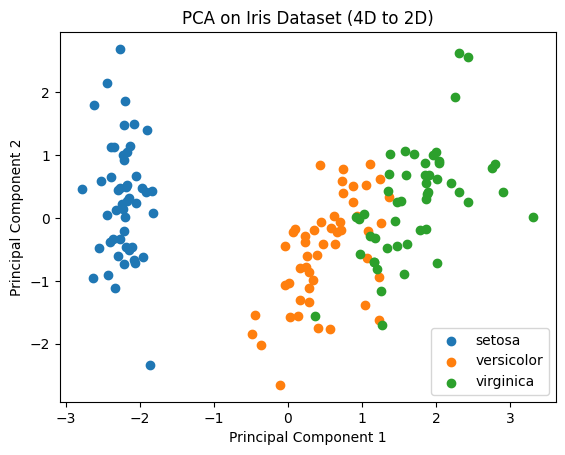

In [5]:
for i in range(3):
    sub = pca_df[pca_df['Species'] == i]
    plt.scatter(sub['PC1'], sub['PC2'], label=iris.target_names[i])
plt.title('PCA on Iris Dataset (4D to 2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()